# 실습 ① 데이터 추출 및 분할 — 연습본

> **[권장 난이도: 초급]** · **[추천 소요 시간: 50분]** · **[교육 과정: 12~13주차 · 4교시]**

PDF 한 편을 **텍스트 / 표 / 이미지** 세 종류로 분리합니다. 멀티모달 RAG의 출발점입니다.

---

## 오늘 만드는 것

```
PDF 문서  ──▶  Unstructured Parser  ──▶  텍스트 / 표 / 이미지
```

## 진행 방법

1. 셀을 **위에서부터 순서대로** 실행합니다 (`Shift + Enter`)
2. `# TODO` 와 `____` 가 있는 곳을 직접 채웁니다
3. 각 단계의 **확인 포인트**를 통과하면 다음으로 넘어갑니다
4. 막히면 바로 손을 드세요. 혼자 10분 이상 붙잡고 있지 마세요

## 완료 기준

- [ ] `figures/` 폴더에 `.jpg` 파일이 생성된다
- [ ] 텍스트 블록 수가 0보다 크다
- [ ] 추출된 이미지를 눈으로 확인했다

## 0. 환경 검증

> ⚠️ **하나라도 ✗가 있으면 진행하지 말고 손을 드세요.**

In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:10s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.9
가상환경 경로: c:\workspace\multimodal-rag\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain : OK
unstructured: OK
chromadb  : OK
tiktoken  : OK
PIL       : OK


## 1. 라이브러리 임포트

아래 셀을 그대로 실행하세요.

| 라이브러리 | 역할 |
| --- | --- |
| `partition_pdf` | PDF를 텍스트·표·이미지로 분리하는 **자동 분리수거 기계** |
| `CharacterTextSplitter` | 긴 텍스트를 일정 크기로 자르는 **작두** |

In [2]:
import os
import time
import pickle
from pathlib import Path

from langchain_text_splitters import CharacterTextSplitter
from unstructured.partition.pdf import partition_pdf

print("임포트 완료")

임포트 완료


## 2. 경로 설정

**TODO 1.** `fname`에 본인이 준비한 PDF 파일 이름을 적으세요.

> ⚠️ **윈도우 주의:** 경로에 한글이나 공백이 들어가면 뒤에서 오류가 납니다.

In [3]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# TODO 1: 본인의 PDF 파일 이름으로 바꾸세요 (예: "invest.pdf")
fname = "invest.pdf"

fpath = str(PROJECT_ROOT / "data") + os.sep

print("프로젝트 루트:", PROJECT_ROOT)
print("PDF 폴더     :", fpath)
print("PDF 존재 여부:", os.path.exists(fpath + fname))

프로젝트 루트: c:\workspace\multimodal-rag\PracticeNotebook
PDF 폴더     : c:\workspace\multimodal-rag\PracticeNotebook\data\
PDF 존재 여부: True


> ✅ **확인 포인트:** `PDF 존재 여부`가 `True`여야 합니다. `False`면 다음 셀은 반드시 실패합니다.

## 3. 추출 함수 만들기

**TODO 2~4.** 빈칸 3개를 채우세요.

| 옵션 | 하는 일 | 빼면 생기는 일 |
| --- | --- | --- |
| `strategy` | 레이아웃 분석 모델로 정밀 추출 | 표·이미지 추출 정확도 급락 |
| `extract_images_in_pdf` | 그림을 별도 파일로 저장 | 이미지가 통째로 사라짐 |
| `infer_table_structure` | 표의 행·열 구조를 추론 | 표가 줄글로 뭉개짐 |

💡 **힌트**
- TODO 2: 정밀 추출 전략의 이름입니다. "high resolution"의 줄임말이에요 (문자열)
- TODO 3: 이미지를 꺼내야 멀티모달이 됩니다 (True / False)
- TODO 4: 표의 구조도 알아내야겠죠 (True / False)

In [4]:
def extract_pdf_elements(path, fname):
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.

    path : 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """
    return partition_pdf(
        filename=path + fname,
        strategy="hi_res",                  # TODO 2: 정밀 추출 전략
        extract_images_in_pdf=True,       # TODO 3: 이미지를 추출할까요?
        infer_table_structure=True,       # TODO 4: 표 구조를 추론할까요?
        chunking_strategy="by_title",     # 타이틀 기준으로 텍스트 분할
        max_characters=4000,              # 최대 4000자로 블록 제한
        new_after_n_chars=3800,           # 3800자 이후 새 블록 생성
        combine_text_under_n_chars=2000,  # 2000자 이하는 결합
        extract_image_block_output_dir=os.path.join(path, "figures"),  # 이미지 저장 경로
    )


print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


## 4. 요소 분류 함수 만들기

추출된 요소를 **텍스트**와 **표** 두 리스트로 나눕니다.

**TODO 5~6.** 어느 리스트에 담아야 할지 채우세요.

💡 **힌트:** 바로 위 `if` 조건문에 무엇이 들어 있는지 보세요. `Table`이면 어디로, `CompositeElement`(텍스트 덩어리)면 어디로 가야 할까요?

In [5]:
def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.

    raw_pdf_elements: unstructured.documents.elements 리스트
    """
    tables = []
    texts = []

    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))     # TODO 5: 표는 어느 리스트로?
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))     # TODO 6: 텍스트는 어느 리스트로?

    return texts, tables


print("categorize_elements 정의 완료")

categorize_elements 정의 완료


## 5. 추출 실행

> ⏱️ **이 셀은 2~3분 걸립니다. 멈춘 것이 아니니 기다리세요.**
>
> 왼쪽 대괄호가 `[*]` 상태면 실행 중이라는 뜻입니다. 숫자로 바뀌면 완료입니다.

In [6]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 — {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 897.10it/s]


추출 완료 — 200.0초 소요
추출된 전체 요소 수: 18


In [7]:
texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수    :", len(tables))

텍스트 블록 수: 9
표 블록 수    : 9


> ✅ **확인 포인트:** `텍스트 블록 수`가 0보다 커야 합니다.
>
> 📌 `표 블록 수`가 0이어도 괜찮습니다. PDF 안의 표가 **이미지로 그려진** 경우에는 표로 잡히지 않습니다.

## 6. 어떤 요소들이 나왔는지 집계

**TODO 7.** 집계 결과를 보고 아래 질문에 답해 보세요.

- 내 PDF에서 가장 많이 나온 요소 타입은 무엇인가?
- `Table`이 잡혔는가? 안 잡혔다면 왜일까?

In [8]:
from collections import Counter

type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 9개
Table                 : 9개


**TODO 7 답을 여기에 적으세요 (더블클릭해서 편집)**

- 가장 많이 나온 요소 타입:
- Table이 잡혔는가? 그 이유는:

## 7. 추출된 이미지 확인

> 📌 **이 단계를 건너뛰지 마세요.** `figures/` 폴더를 **직접 열어서** 그림이 진짜로 나왔는지 눈으로 확인해야 합니다.

In [9]:
figures_dir = Path(fpath) / "figures"

if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    print(f"추출된 이미지: {len(image_files)}개\n")
    for f in image_files[:10]:
        print(f"  {f.name}  ({f.stat().st_size // 1024} KB)")
else:
    print("✗ figures 폴더가 없습니다.")
    print("  → TODO 2, TODO 3 을 다시 확인하세요.")

추출된 이미지: 138개

  figure-1-1.jpg  (280 KB)
  figure-1-2.jpg  (22 KB)
  figure-10-30.jpg  (7 KB)
  figure-10-31.jpg  (45 KB)
  figure-10-32.jpg  (39 KB)
  figure-11-100.jpg  (0 KB)
  figure-11-101.jpg  (0 KB)
  figure-11-102.jpg  (0 KB)
  figure-11-103.jpg  (0 KB)
  figure-11-104.jpg  (0 KB)


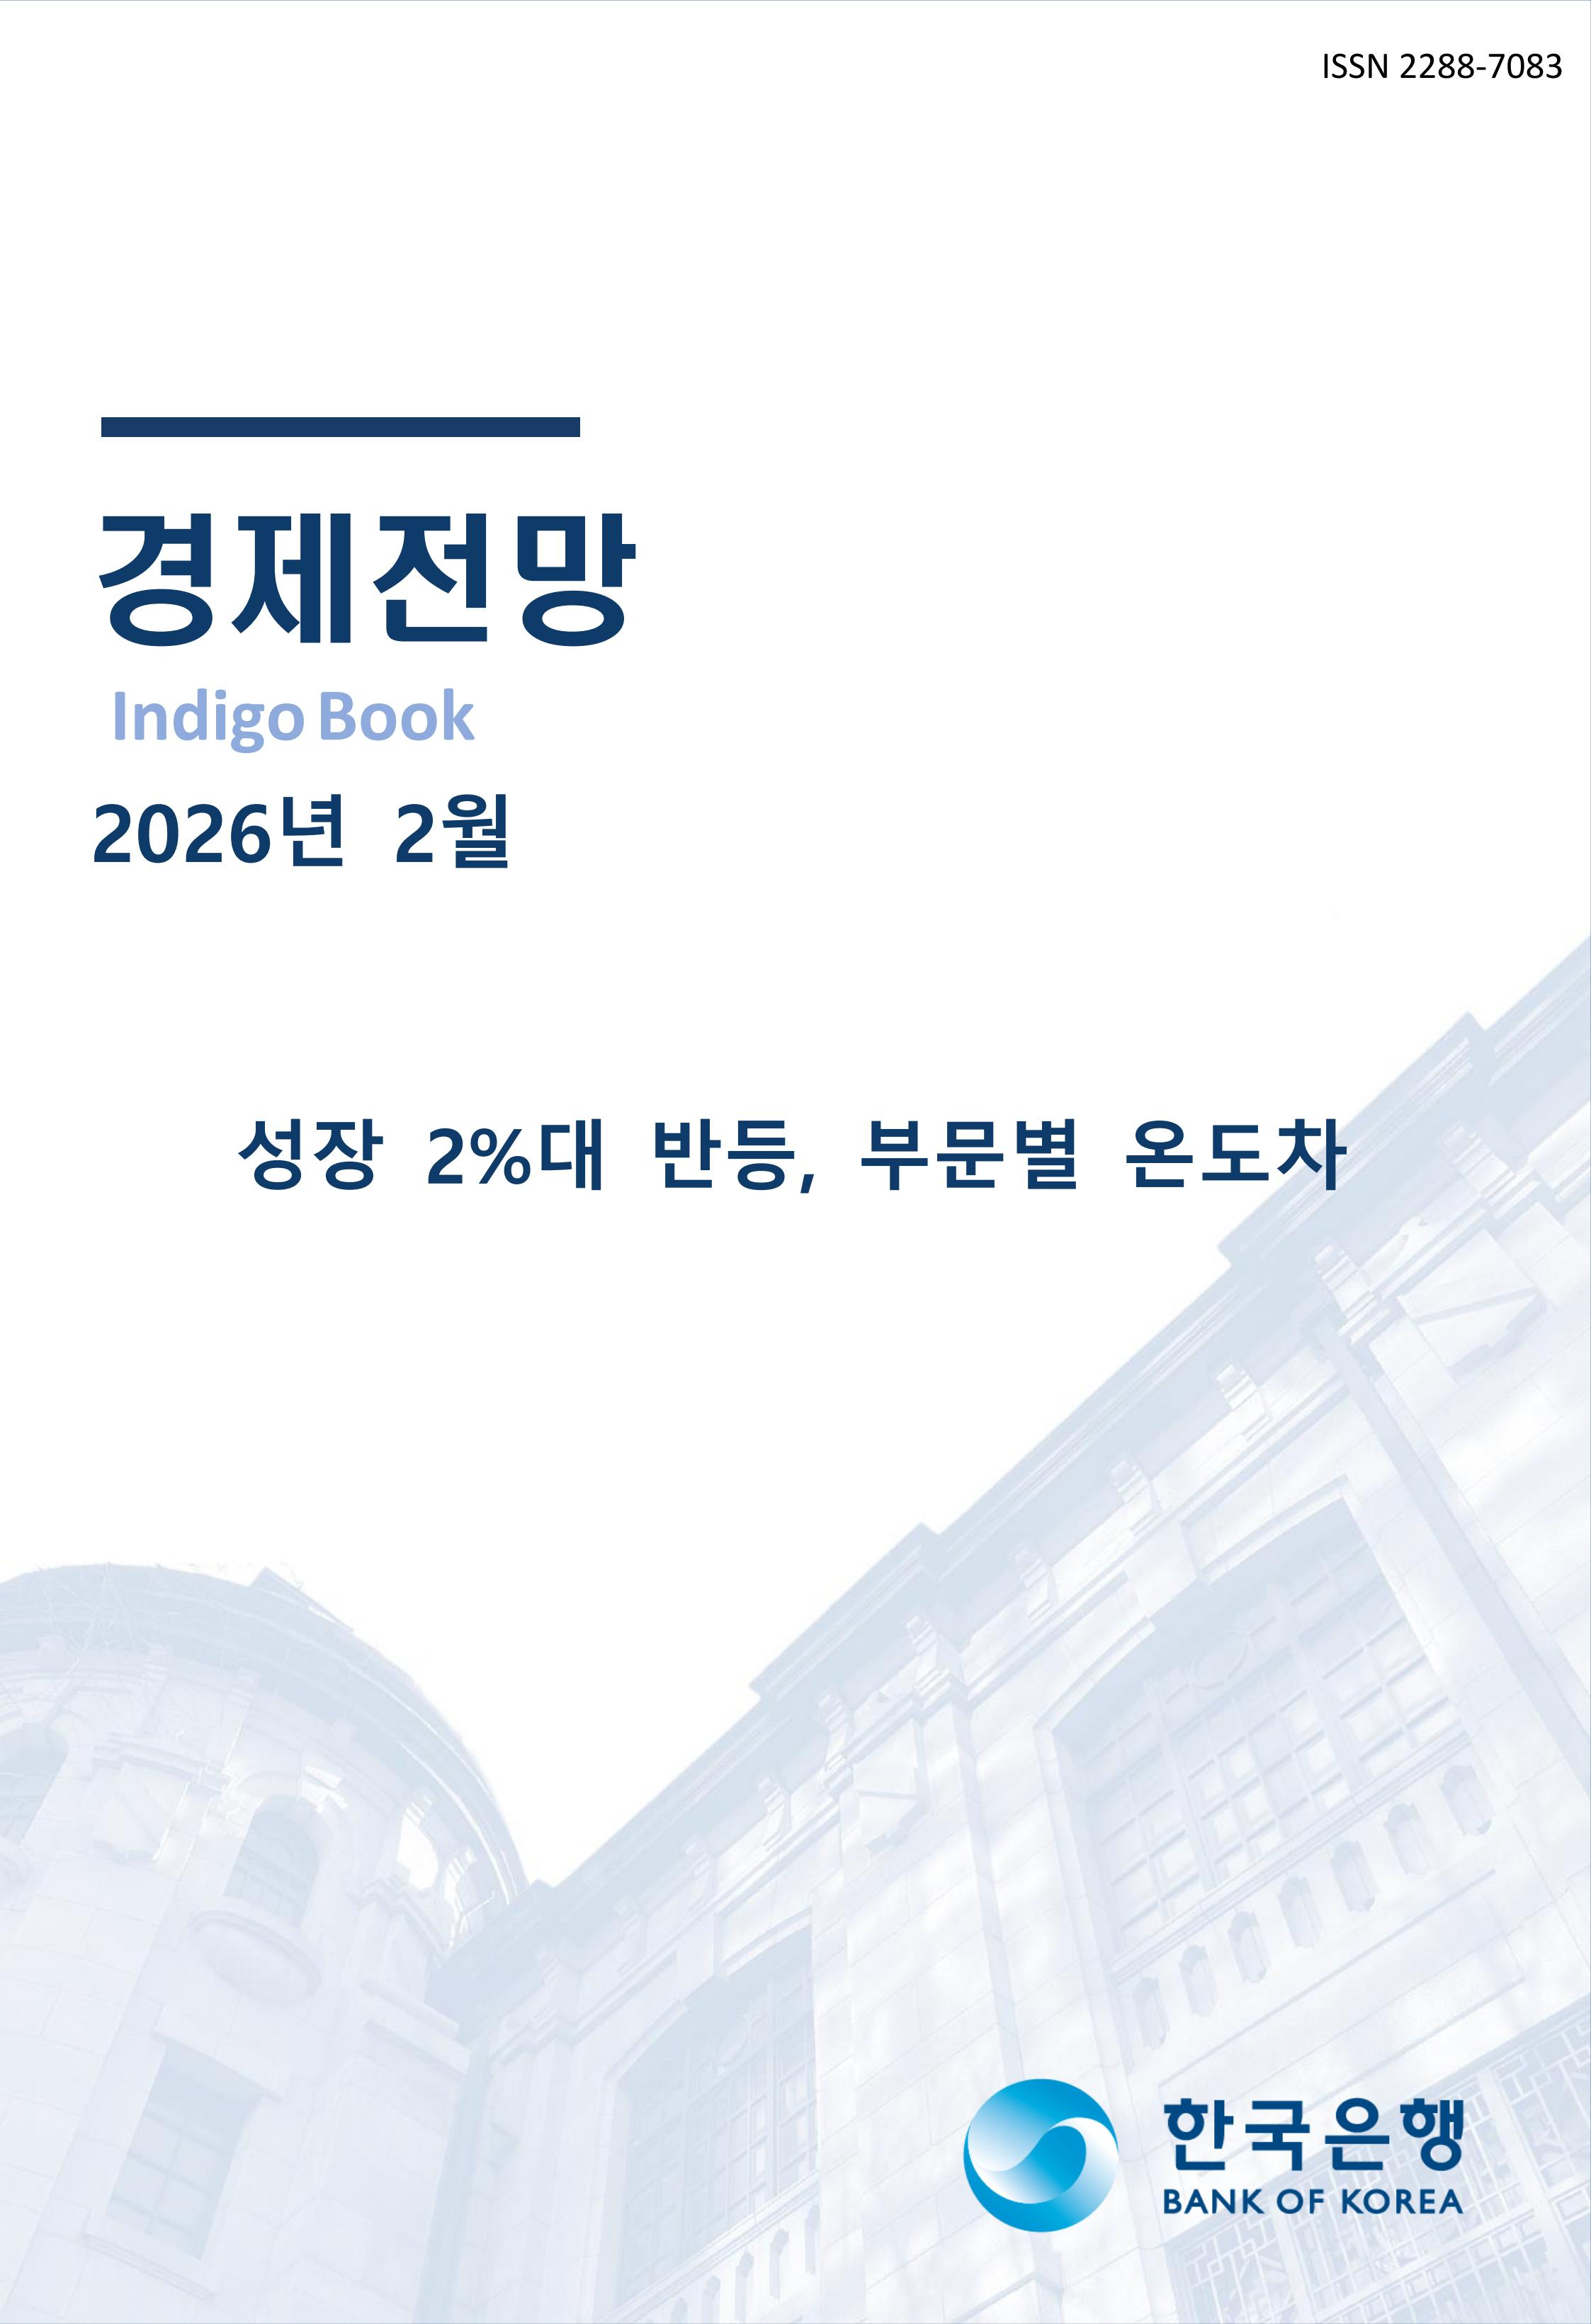

In [10]:
# 첫 번째 이미지를 노트북에서 직접 확인
from IPython.display import Image, display

if figures_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=200))
else:
    print("표시할 이미지가 없습니다.")

> ✅ **확인 포인트:** 이미지가 화면에 보이면 성공입니다. 안 보이면 `figures/` 폴더가 비어 있다는 뜻이니 TODO 2, 3을 확인하세요.

## 8. 텍스트 분할

추출된 텍스트를 **2000자 단위로 다시 자릅니다.**

**TODO 8.** 겹침(overlap) 값을 채우세요.

💡 **힌트:** 문장이 블록 경계에서 잘려 뜻이 사라지는 것을 막기 위해 앞뒤를 조금씩 겹치게 자릅니다. 교재 기준값은 **200**입니다.

In [11]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=200,    # TODO 8: 청크 간 겹칠 글자 수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))

원본 블록 수  : 9
분할 후 블록 수: 6
전체 글자 수  : 7056


## 9. 분할 결과 비교

원본과 분할된 텍스트의 첫 번째 요소를 비교합니다.

In [12]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

[원본 texts[0]] 앞 300자
ISSN 2288-7083 경제전망 Indigo Book 2026년 2월 성장 2%대 반등, 부문별 온도차

ISSN 2288-7083

경제전망

er Oy BANK OF KOREA

부문별 담당자

부 문

담 당 팀

담 당 자

[분할 texts_2k_token[0]] 앞 300자
ISSN 2288-7083 경제전망 Indigo Book 2026년 2월 성장 2%대 반등, 부문별 온도차

ISSN 2288-7083

경제전망

er Oy BANK OF KOREA

부문별 담당자

부 문

담 당 팀

담 당 자 물가동향팀

장태윤

조사총괄팀

이종웅 최영우 고민지

경제전망 결과 리뷰

물가동향팀

장수정 강보민

장태윤

금융통화위원회실

이승호

차 례

경제전망 요약

국내외 여건 및 전망 <부록 2> 주요 이슈 분석목록

2

14

20

22

31

33

35

40

40

41

경제전망 


## 10. 다음 교시를 위한 저장

추출에 2~3분이 걸리므로 결과를 파일로 저장해 둡니다. 5교시에서 그대로 불러 씁니다.

In [13]:
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "extracted.pkl", "wb") as f:
    pickle.dump(
        {"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token},
        f,
    )

print("저장 완료:", output_dir / "extracted.pkl")

저장 완료: c:\workspace\multimodal-rag\PracticeNotebook\data\processed\extracted.pkl


---

## ✅ 체크포인트 1 — 모두 체크되면 4교시 완료

- [ ] `figures/` 폴더가 생기고 그 안에 `.jpg` 파일이 있다
- [ ] `len(texts)`와 `len(texts_2k_token)`이 둘 다 0보다 크다
- [ ] 폴더를 직접 열어 추출된 그림을 **눈으로** 확인했다
- [ ] `data/processed/extracted.pkl` 파일이 생성되었다
- [ ] TODO 1~8을 모두 채웠다

## 생각해 볼 질문 (답을 적어보세요)

더블클릭해서 편집하세요. 정답을 맞히는 것보다 **본인 말로 써 보는 것**이 중요합니다.

**Q1. `strategy="hi_res"`를 빼면 왜 표와 이미지가 잘 안 잡힐까요?**

답:

**Q2. 텍스트를 자를 때 왜 200자를 겹치게 할까요? 겹치지 않으면 어떤 일이 생길까요?**

답:

**Q3. 지금 단계에서 이미지는 파일로 저장만 되어 있습니다. 이 상태로는 검색이 안 되는데, 왜 그럴까요?**

답:

## 자주 나는 에러

| 증상 | 원인 | 해결 |
| --- | --- | --- |
| `PDFInfoNotInstalledError` | Poppler 미설치 / Path 누락 | 설치 후 **커널 재시작** |
| `TesseractNotFoundError` | Tesseract Path 누락 | `C:\Program Files\Tesseract-OCR` 추가 후 재시작 |
| `FileNotFoundError` | PDF 파일명/경로 오류 | TODO 1과 `PDF 존재 여부` 확인 |
| `figures/`가 비어 있음 | TODO 2, 3 미완성 | 두 옵션 모두 확인 |
| `NameError: texts` | 앞 셀을 안 돌림 | 위에서부터 순서대로 재실행 |
| 파싱이 끝나지 않음 | 정상. `hi_res`는 느림 | 2~3분 대기 |

> 그래도 안 되면 **커널 재시작 후 위에서부터 전체 재실행**하세요. 변수가 꼬여 생기는 오류가 의외로 많습니다.